# $\mathrm{Exercise\ I:\ Regression\ of\ Concrete\ Compressive\ Strength}$

## $\mathrm{Task\ Notebook}$

Data: **Concrete_Data.csv** (StudOn)

$\displaystyle
\begin{aligned}
&\text{In this exercise, we train a model that predicts the compressive strength of concrete.}\\[5pt]
&\text{The inputs are the amounts of the mixture components and the age of the concrete.}\\[5pt]
&\text{Because the output is a number (strength in MPa), this is a regression problem.}\\[5pt]
&\text{Work through the tasks step by step. The solution will be provided in StudOn one week later.}
\end{aligned}
$

## $\mathrm{What\ you\ will\ learn}$

$\displaystyle
\begin{aligned}
&\text{1. Load a dataset and turn it into a Pandas DataFrame.}\\[5pt]
&\text{2. Understand the data and find relevant features with a correlation analysis.}\\[5pt]
&\text{3. Visualise the relationships between the features and the target.}\\[5pt]
&\text{4. Prepare the data: features X, target y, training and test set.}\\[5pt]
&\text{5. Train regression models: linear, polynomial, decision tree and k-NN.}\\[5pt]
&\text{6. Evaluate the models with MAE, MSE, RMSE and R² - and the maximum deviation.}\\[5pt]
&\text{7. Check the model quality with plots and use the model for a new mixture.}
\end{aligned}
$

## $\mathrm{The\ workflow}$

| Step | What we do | Library |
|---|---|---|
| 1 | Load the data | Pandas |
| 2 | Understand the data | Pandas |
| 3 | Visualise the relationships | Matplotlib |
| 4 | Prepare the data | scikit-learn |
| 5 | Train and test the models | scikit-learn |
| 6 | Evaluate the models | scikit-learn, Matplotlib |

> **Tip:** Run the cells from top to bottom. If something behaves strangely, use *Runtime → Restart and run all* (Colab) or *Kernel → Restart & Run All* (Jupyter).

> **Use generative AI** (ChatGPT, Gemini, …) to generate code, add comments and explain lines you do not understand – but always check that the result makes sense.

# $\mathrm{1.0\ Importing\ the\ Libraries}$

$\displaystyle
\begin{aligned}
&\text{We first import all libraries that we need in this notebook.}\\[5pt]
&\text{NumPy: calculations with arrays.}\\[5pt]
&\text{Pandas: working with tables (DataFrames).}\\[5pt]
&\text{Matplotlib: plotting.}\\[5pt]
&\text{scikit-learn: data splitting, scaling, the regression models and the evaluation metrics.}
\end{aligned}
$

> **Task:** Think about which libraries and frameworks you need for this exercise and import them.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import max_error, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeRegressor

%matplotlib inline

# $\mathrm{2.0\ Loading\ the\ Data}$

## $\mathrm{2.1\ The\ Concrete\ Compressive\ Strength\ Dataset}$

$\displaystyle
\begin{aligned}
&\text{During concrete production, samples are cast into standardised test cubes.}\\[5pt]
&\text{After curing, a testing machine loads each cube until it fails.}\\[5pt]
&\text{Compressive strength = maximum force / loaded area, in megapascal (MPa = N/mm²).}\\[5pt]
&\text{The test is expensive and takes days to weeks - a model could estimate the strength in advance.}
\end{aligned}
$

## $\mathrm{2.2\ How\ the\ Data\ is\ Loaded}$

Please use the dataset **Concrete_Data.csv** that you will find in StudOn. To use the file in Colab, you can:
- upload it directly in the notebook (folder icon on the left-hand side → upload), or
- upload it to Google Drive and connect Drive to Colab.

The file contains one row per concrete sample (1030 rows) and nine columns:

| Column | Meaning | Unit | Role |
|---|---|---|---|
| `cement` | cement content | kg/m³ | feature |
| `slag` | blast furnace slag | kg/m³ | feature |
| `flyash` | fly ash | kg/m³ | feature |
| `water` | water | kg/m³ | feature |
| `superplasticizer` | superplasticizer (makes the concrete flow with less water) | kg/m³ | feature |
| `coarseaggregate` | coarse aggregate (gravel) | kg/m³ | feature |
| `fineaggregate` | fine aggregate (sand) | kg/m³ | feature |
| `age` | age of the sample at testing | days | feature |
| `csMPa` | compressive strength | MPa | **target** |



> **Task:** Load the file, get an overview of the data structure and comment your code briefly. Which columns are the features, and which column is the target variable?

In [2]:
# load .csv file into pd dataframe
data_path = Path("Concrete_Data.csv")
if not data_path.exists():
    data_path = Path("1_regression") / data_path

df = pd.read_csv(data_path)
# print a few rows
df.head()

,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age,csMPa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


# $\mathrm{3.0\ Understanding\ the\ Data}$

$\displaystyle
\begin{aligned}
&\text{Before training a model, we must understand the structure of the data.}\\[5pt]
&\text{How many rows and columns? Which data types? Are values missing or duplicated?}\\[5pt]
&\text{In which range do the values lie - and are the units very different?}
\end{aligned}
$

> **Task:** Check the size, the data types, missing values and duplicates. Use describe() to look at the value ranges.

In [3]:
# Size: rows = samples, columns = 8 features + 1 target
print("Shape:", df.shape)

# Data types and non-null counts per column
df.info()

# Missing values per column
print("\nMissing values per column:")
print(df.isna().sum())

# Fully identical rows
print("\nDuplicate rows:", df.duplicated().sum())

# Value ranges: note the very different scales (age in days vs. kg/m³)
df.describe().T

Shape: (1030, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cement            1030 non-null   float64
 1   slag              1030 non-null   float64
 2   flyash            1030 non-null   float64
 3   water             1030 non-null   float64
 4   superplasticizer  1030 non-null   float64
 5   coarseaggregate   1030 non-null   float64
 6   fineaggregate     1030 non-null   float64
 7   age               1030 non-null   int64  
 8   csMPa             1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB

Missing values per column:
cement              0
slag                0
flyash              0
water               0
superplasticizer    0
coarseaggregate     0
fineaggregate       0
age                 0
csMPa               0
dtype: int64

Duplicate rows: 25


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.167864,104.506364,102.00,192.375,272.900,350.000,540.0
slag,1030.0,73.895825,86.279342,0.00,0.000,22.000,142.950,359.4
flyash,1030.0,54.188350,63.997004,0.00,0.000,0.000,118.300,200.1
water,1030.0,181.567282,21.354219,121.80,164.900,185.000,192.000,247.0
superplasticizer,1030.0,6.204660,5.973841,0.00,0.000,6.400,10.200,32.2
coarseaggregate,1030.0,972.918932,77.753954,801.00,932.000,968.000,1029.400,1145.0
fineaggregate,1030.0,773.580485,80.175980,594.00,730.950,779.500,824.000,992.6
age,1030.0,45.662136,63.169912,1.00,7.000,28.000,56.000,365.0
csMPa,1030.0,35.817961,16.705742,2.33,23.710,34.445,46.135,82.6


In [4]:
# we got 25 duplicate rows --> drop them
df = df.drop_duplicates()
df.head()

,cement,slag,flyash,water,superplasticizer,coarseaggregate,fineaggregate,age,csMPa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


# $\mathrm{4.0\ Correlation\ Analysis:\ Which\ Features\ Matter?}$

$\displaystyle
\begin{aligned}
&\text{The Pearson correlation coefficient r measures the strength of a linear relationship (-1 to +1).}\\[5pt]
&\text{r near +1: both increase together; r near -1: one decreases when the other increases; r near 0: no linear relationship.}\\[5pt]
&\text{corr() calculates r for every pair of columns - the result is the correlation matrix.}
\end{aligned}
$

> **Attention:** correlation does not imply causation – and r only captures *linear* relationships.



> **Task:** Calculate a correlation matrix between the features and the target variable. What are the most significant factors, and is this plausible?

In [5]:
# correlation matrix of all features (and the target)
corr = df.corr()

# Correlation of each feature with the target, sorted by absolute strength
corr["csMPa"].drop("csMPa").sort_values(key=abs, ascending=False)

cement              0.488283
superplasticizer    0.344209
age                 0.337367
water              -0.269624
fineaggregate      -0.186448
coarseaggregate    -0.144717
slag                0.103374
flyash             -0.080648
Name: csMPa, dtype: float64

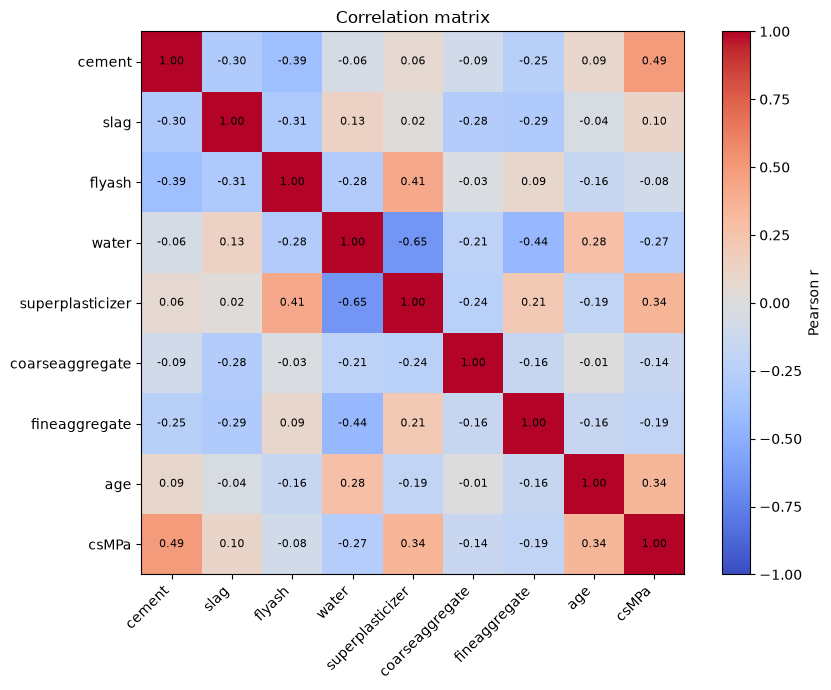

In [6]:
# Heatmap of the full correlation matrix
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)

# Write r into each cell
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(im, label="Pearson r")
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

looks plausible to me. The most important features are Cement, Water, Superplasticizer, and Age.

- Cement is the main binder, so more of it should increase the concrete strength.
- Water is negative. A higher water-to-cement ratio makes the concrete weaker.
- Superplasticizer is positive because it lets you use less water and still get workable concrete.
- Age is also positive because concreate hardens over time

we have to keep in mind those are only linear relationships.

# $\mathrm{5.0\ Visualising\ the\ Relationships}$

$\displaystyle
\begin{aligned}
&\text{Scatter plots show each feature against the strength.}\\[5pt]
&\text{They reveal non-linear patterns that the correlation coefficient cannot show.}
\end{aligned}
$

> **Task:** Visualise the relationships between the most important features and the target variable. Which relationships look linear, which do not?

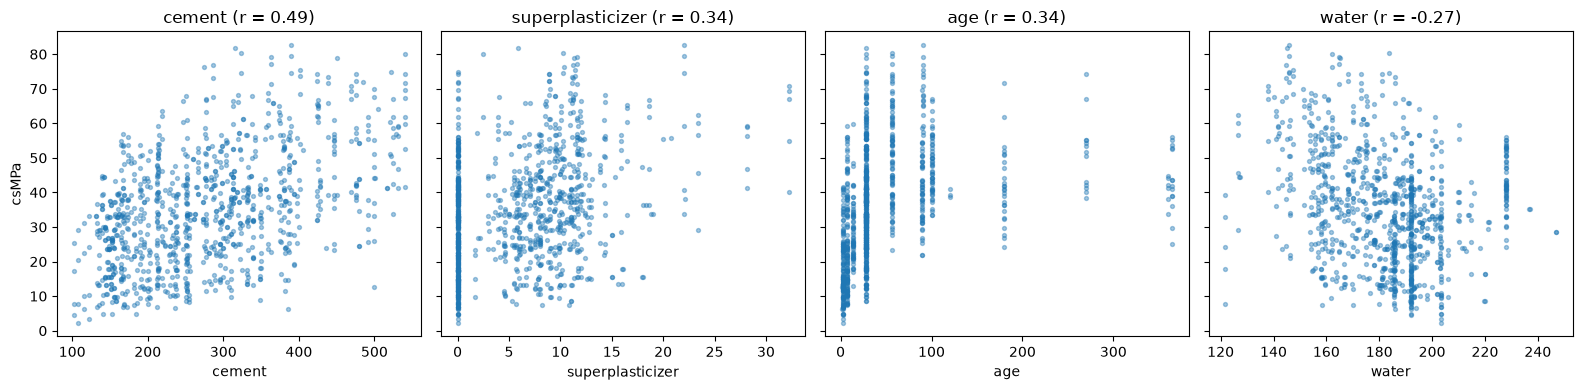

In [7]:
# The four features with the strongest correlation to the target
r = corr["csMPa"].drop("csMPa").sort_values(key=abs, ascending=False)
top_features = r.index[:4]

# One scatter plot per important feature vs. compressive strength
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, feature in zip(axes, top_features):
    ax.scatter(df[feature], df["csMPa"], s=8, alpha=0.4)
    ax.set_title(f"{feature} (r = {r[feature]:.2f})")
    ax.set_xlabel(feature)
axes[0].set_ylabel("csMPa")

plt.tight_layout()
plt.show()

- **Cement**: linear (positive)
- **Water**: linear (negative)
- **Superplasticizer**: many zeros (maybe some mixtures dont have it at all). After that a positive trend that seems to flatten out
- **Age**: non-linear (positive). Rises quickly at first and the also flattends out over time


# $\mathrm{6.0\ Data\ Preparation}$

## $\mathrm{6.1\ Features\ X\ and\ Target\ y}$

$\displaystyle
\begin{aligned}
&\text{Features X: the inputs of the model - the eight columns that describe the mixture and the age.}\\[5pt]
&\text{Target y: the output we want to predict - the compressive strength csMPa.}
\end{aligned}
$

## $\mathrm{6.2\ Training\ Set\ and\ Test\ Set}$

$\displaystyle
\begin{aligned}
&\text{We must test the model on samples it has never seen during training.}\\[5pt]
&\text{Otherwise, we only measure how well it memorised the data - not how well it generalises.}
\end{aligned}
$

| Argument | Meaning in this notebook |
|---|---|
| `test_size=0.3` | 30 % of the samples (309) are kept for testing, 70 % (721) are used for training |
| `random_state=42` | fixes the random split, so everybody gets exactly the same result |



> **Task:** Prepare the data in a training and a test dataset to train and test the regression model in a later stage. Do some research to understand the reason.

In [8]:
# drop target from training/testing data
X = df.drop(columns="csMPa")
y = df["csMPa"]

# train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("Training set:", X_train.shape, "| Test set:", X_test.shape)

Training set: (703, 8) | Test set: (302, 8)


# $\mathrm{7.0\ How\ We\ Evaluate\ the\ Models}$

$\displaystyle
\begin{aligned}
&\text{All metrics are built from the errors (residuals) of the test samples:}
\end{aligned}
$

$$e_i = y_i - \hat{y}_i$$

| Metric | Formula | Meaning |
|---|---|---|
| MAE | $\frac{1}{n}\sum_i |y_i-\hat{y}_i|$ | average deviation in MPa |
| MSE | $\frac{1}{n}\sum_i (y_i-\hat{y}_i)^2$ | large errors count more (MPa²) |
| RMSE | $\sqrt{\mathrm{MSE}}$ | typical error size in MPa |
| R² | $1-\frac{\sum_i (y_i-\hat{y}_i)^2}{\sum_i (y_i-\bar{y})^2}$ | share of the variation explained (1 = perfect, 0 = no better than the mean) |
| max. deviation | $\max_i |y_i-\hat{y}_i|$ | worst single prediction in MPa |

We also calculate R² on the **training** data: a large gap between training and test R² indicates overfitting.



> **Task:** Which metrics do you use to answer the question "What are the average and maximum deviations?"

# $\mathrm{8.0\ Model\ 1:\ Simple\ Linear\ Regression}$

$\displaystyle
\begin{aligned}
&\text{One feature only: the strongest one, cement.}\\[5pt]
&\text{The model is a straight line: y = b0 + b1 * cement.}\\[5pt]
&\text{fit() finds b0 and b1 with the least squares method.}
\end{aligned}
$

> **Task:** Train a first model with one feature only. How good is it?

In [9]:
# dict to collect evaluation results of different models
results = {}

def evaluate(name, model, X_tr, X_te):
    y_pred = model.predict(X_te)
    mse = mean_squared_error(y_test, y_pred)
    results[name] = {
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "max dev": max_error(y_test, y_pred),
        "R² train": r2_score(y_train, model.predict(X_tr)),
        "R² test": r2_score(y_test, y_pred),
    }
    # for metric, value in results[name].items():
    #     print(f"{metric}: {value}")
    return results

In [10]:
# linear regression on the strongest feature (cement) only
lin_simple = LinearRegression().fit(X_train[["cement"]], y_train)
# print the fitted values (just for fun)
print(f"csMPa = {lin_simple.intercept_:.2f} + {lin_simple.coef_[0]:.4f} * cement")

evaluate("Linear (cement only)", lin_simple, X_train[["cement"]], X_test[["cement"]])
pd.DataFrame(results).T.round(3)

csMPa = 13.74 + 0.0771 * cement


,MAE,MSE,RMSE,max dev,R² train,R² test
Linear (cement only),12.301,225.873,15.029,43.726,0.25,0.214


# $\mathrm{9.0\ Model\ 2:\ Multiple\ Linear\ Regression}$

$\displaystyle
\begin{aligned}
&\text{Now all eight features: y = b0 + b1*x1 + b2*x2 + ... + b8*x8.}\\[5pt]
&\text{Each coefficient bi tells how much the strength changes per kg/m³ (or per day) of that feature.}
\end{aligned}
$

In [11]:
# Multiple linear regression with all eight features
lin_multi = LinearRegression().fit(X_train, y_train)

# print the coefficients for each feature
print(pd.Series(lin_multi.coef_, index=X.columns).round(4))

evaluate("Linear (all features)", lin_multi, X_train, X_test)
pd.DataFrame(results).T.round(3)

cement              0.1227
slag                0.1072
flyash              0.0943
water              -0.1083
superplasticizer    0.3491
coarseaggregate     0.0186
fineaggregate       0.0298
age                 0.1119
dtype: float64


,MAE,MSE,RMSE,max dev,R² train,R² test
Linear (cement only),12.301,225.873,15.029,43.726,0.250,0.214
Linear (all features),8.984,126.209,11.234,36.406,0.622,0.561


# $\mathrm{10.0\ Model\ 3:\ Polynomial\ Regression}$

$\displaystyle
\begin{aligned}
&\text{Polynomial regression adds new features: squares (x²), cubes (x³) and products (x1*x2).}\\[5pt]
&\text{The model is still linear in its parameters - so it is fitted with least squares, too.}\\[5pt]
&\text{The degree d is a complexity knob: too small = underfitting, too large = overfitting.}
\end{aligned}
$

> **Task:** Test non-linear models. Try polynomial regression with degree 2 and 3.

In [12]:
# build it as a pipeline
# note that we also need a scaler here, because ply-features can create large values
for degree in [2, 3]:
    poly = make_pipeline(StandardScaler(), PolynomialFeatures(degree), LinearRegression())
    poly.fit(X_train, y_train)
    evaluate(f"Polynomial (degree {degree})", poly, X_train, X_test)

pd.DataFrame(results).T.round(3)

,MAE,MSE,RMSE,max dev,R² train,R² test
Linear (cement only),12.301,225.873,15.029,43.726,0.250,0.214
Linear (all features),8.984,126.209,11.234,36.406,0.622,0.561
Polynomial (degree 2),6.267,67.983,8.245,28.701,0.816,0.763
Polynomial (degree 3),5.294,64.963,8.060,44.736,0.934,0.774


# $\mathrm{11.0\ Model\ 4:\ Decision\ Tree\ Regression}$

$\displaystyle
\begin{aligned}
&\text{A regression tree splits the data with if-then rules (e.g. age <= 21 days).}\\[5pt]
&\text{Each leaf predicts the average strength of its training samples.}\\[5pt]
&\text{max_depth limits the number of questions - the main complexity knob of the tree.}
\end{aligned}
$

In [13]:
# max_depth limits the number of if-then questions; None = grow until every leaf is pure
for depth in [3, 5, 10, None]:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42).fit(X_train, y_train)
    evaluate(f"Decision tree (max_depth={depth})", tree, X_train, X_test)

pd.DataFrame(results).T.round(3)

,MAE,MSE,RMSE,max dev,R² train,R² test
Linear (cement only),12.301,225.873,15.029,43.726,0.250,0.214
Linear (all features),8.984,126.209,11.234,36.406,0.622,0.561
Polynomial (degree 2),6.267,67.983,8.245,28.701,0.816,0.763
Polynomial (degree 3),5.294,64.963,8.060,44.736,0.934,0.774
Decision tree (max_depth=3),8.333,117.417,10.836,42.107,0.611,0.592
Decision tree (max_depth=5),7.060,82.705,9.094,38.989,0.813,0.712
Decision tree (max_depth=10),4.823,46.406,6.812,31.150,0.974,0.839
Decision tree (max_depth=None),4.336,43.481,6.594,34.070,0.996,0.849


# $\mathrm{12.0\ Model\ 5:\ k-Nearest\ Neighbours\ Regression}$

$\displaystyle
\begin{aligned}
&\text{k-NN predicts the average strength of the k most similar mixtures in the training data.}\\[5pt]
&\text{Similar = small Euclidean distance between the feature values.}\\[5pt]
&\text{Because it uses distances, the features should be scaled first.}
\end{aligned}
$

In [14]:
# k-NN uses distances -> scale the features 
for k in [3, 5, 10]:
    knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k)).fit(X_train, y_train)
    evaluate(f"k-NN (k={k})", knn, X_train, X_test)

pd.DataFrame(results).T.round(3)

,MAE,MSE,RMSE,max dev,R² train,R² test
Linear (cement only),12.301,225.873,15.029,43.726,0.250,0.214
Linear (all features),8.984,126.209,11.234,36.406,0.622,0.561
Polynomial (degree 2),6.267,67.983,8.245,28.701,0.816,0.763
Polynomial (degree 3),5.294,64.963,8.060,44.736,0.934,0.774
Decision tree (max_depth=3),8.333,117.417,10.836,42.107,0.611,0.592
Decision tree (max_depth=5),7.060,82.705,9.094,38.989,0.813,0.712
Decision tree (max_depth=10),4.823,46.406,6.812,31.150,0.974,0.839
Decision tree (max_depth=None),4.336,43.481,6.594,34.070,0.996,0.849
k-NN (k=3),7.019,89.233,9.446,36.433,0.849,0.690
k-NN (k=5),7.830,101.407,10.070,32.976,0.800,0.647


# $\mathrm{13.0\ Reducing\ the\ Features}$

$\displaystyle
\begin{aligned}
&\text{Do we need all eight features? We test the four features with the strongest correlation.}\\[5pt]
&\text{Fewer features = simpler model and fewer measurements - but maybe less accuracy.}
\end{aligned}
$

> **Task:** Test reducing the features to the most relevant ones. How does the model quality change?

In [ ]:
# Keep only the four features with the strongest correlation (see above)
print("Features used:", list(top_features))
X_train_4, X_test_4 = X_train[top_features], X_test[top_features]

# Retrain the best variant of each model type with 4 instead of 8 features
models_4 = {
    "Linear": LinearRegression(),
    "Polynomial (degree 2)": make_pipeline(StandardScaler(), PolynomialFeatures(2), LinearRegression()),
    "Decision tree (max_depth=10)": DecisionTreeRegressor(max_depth=10, random_state=42),
    "k-NN (k=3)": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=3)),
}
for name, model in models_4.items():
    model.fit(X_train_4, y_train)
    evaluate(f"{name} - 4 features", model, X_train_4, X_test_4)

pd.DataFrame(results).T.round(3).filter(like="4 features", axis=0)

Features used: ['cement', 'superplasticizer', 'age', 'water']


,MAE,MSE,RMSE,max dev,R² train,R² test
Linear - 4 features,9.825,154.499,12.430,41.894,0.501,0.462
Polynomial (degree 2) - 4 features,7.661,96.308,9.814,38.688,0.674,0.665
Decision tree (max_depth=10) - 4 features,5.510,58.914,7.676,35.001,0.948,0.795
k-NN (k=3) - 4 features,6.911,80.562,8.976,29.190,0.851,0.720


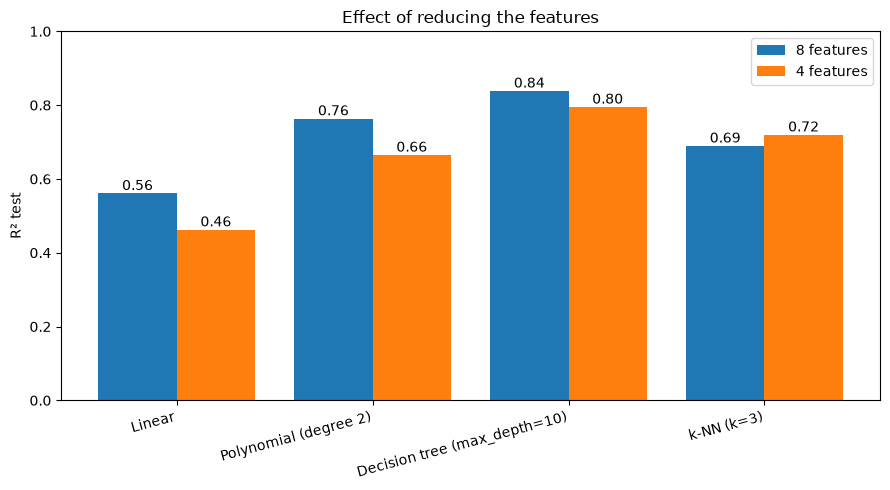

In [16]:
# Test  with all 8 features vs. the 4 strongest features, per model type
names_8 = ["Linear (all features)", "Polynomial (degree 2)", "Decision tree (max_depth=10)", "k-NN (k=3)"]
r2_8 = [results[n]["R² test"] for n in names_8]
r2_4 = [results[f"{n} - 4 features"]["R² test"] for n in models_4]

x = np.arange(len(models_4))
fig, ax = plt.subplots(figsize=(9, 5))
bars_8 = ax.bar(x - 0.2, r2_8, width=0.4, label="8 features")
bars_4 = ax.bar(x + 0.2, r2_4, width=0.4, label="4 features")
ax.bar_label(bars_8, fmt="%.2f")
ax.bar_label(bars_4, fmt="%.2f")
ax.set_xticks(x, models_4.keys(), rotation=15, ha="right")
ax.set_ylabel("R² test")
ax.set_ylim(0, 1)
ax.set_title("Effect of reducing the features")
ax.legend()
plt.tight_layout()
plt.show()

**Regression:**
We see some performance decrease, but not too bad. This is expected, since the correlation of the removed features with the target variable is not that strong.

**Decision tree:**
Also some slight decrease in performance, but the model remains relatively robust to the removal of less important features.

**k-NN:**
Even a increase in performance. With fewer, but more relevant features, the distances are dominated by the important features (basically less noise in the data). 

# $\mathrm{14.0\ Comparing\ All\ Models}$

$\displaystyle
\begin{aligned}
&\text{We collect all results in one table and sort it by the test R².}\\[5pt]
&\text{Bonus: a random forest averages many decision trees and is often a strong model for tabular data.}
\end{aligned}
$

In [17]:
from sklearn.ensemble import RandomForestRegressor

# Bonus: a random forest averages 200 decision trees, each trained on a random sample of the data
forest = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_train, y_train)
evaluate("Random forest", forest, X_train, X_test)

# All models in one table, best test R² first
comparison = pd.DataFrame(results).T.sort_values("R² test", ascending=False)
comparison.round(3)

,MAE,MSE,RMSE,max dev,R² train,R² test
Random forest,3.776,29.153,5.399,31.598,0.983,0.899
Decision tree (max_depth=None),4.336,43.481,6.594,34.070,0.996,0.849
Decision tree (max_depth=10),4.823,46.406,6.812,31.150,0.974,0.839
Decision tree (max_depth=10) - 4 features,5.510,58.914,7.676,35.001,0.948,0.795
Polynomial (degree 3),5.294,64.963,8.060,44.736,0.934,0.774
Polynomial (degree 2),6.267,67.983,8.245,28.701,0.816,0.763
k-NN (k=3) - 4 features,6.911,80.562,8.976,29.190,0.851,0.720
Decision tree (max_depth=5),7.060,82.705,9.094,38.989,0.813,0.712
k-NN (k=3),7.019,89.233,9.446,36.433,0.849,0.690
Polynomial (degree 2) - 4 features,7.661,96.308,9.814,38.688,0.674,0.665


# $\mathrm{15.0\ Visualisation\ of\ the\ Model\ Quality}$

$\displaystyle
\begin{aligned}
&\text{Predicted vs. measured: a perfect model puts all points on the diagonal y = x.}\\[5pt]
&\text{Residual plot: the errors should scatter randomly around 0 - patterns mean that the model misses information.}
\end{aligned}
$

> **Task:** Visualise the model quality by comparing the actual target values of the test data with the values predicted by the model. Also plot the residuals.

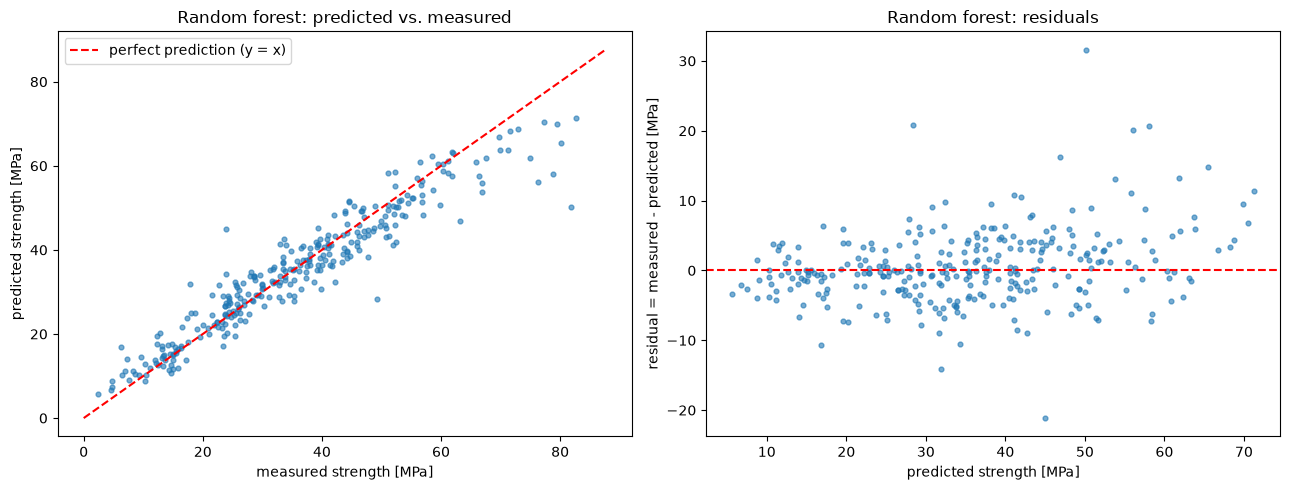

In [18]:
# Predictions of the best model (random forest) on the unseen test data
y_pred = forest.predict(X_test)
residuals = y_test - y_pred

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# pred vs. measured
ax1.scatter(y_test, y_pred, s=12, alpha=0.6)
lims = [0, y_test.max() + 5]
ax1.plot(lims, lims, "r--", label="perfect prediction (y = x)")
ax1.set_xlabel("measured strength [MPa]")
ax1.set_ylabel("predicted strength [MPa]")
ax1.set_title("Random forest: predicted vs. measured")
ax1.legend()

# residuals vs. predicted
ax2.scatter(y_pred, residuals, s=12, alpha=0.6)
ax2.axhline(0, color="r", linestyle="--")
ax2.set_xlabel("predicted strength [MPa]")
ax2.set_ylabel("residual = measured - predicted [MPa]")
ax2.set_title("Random forest: residuals")

plt.tight_layout()
plt.show()

# $\mathrm{16.0\ Using\ the\ Model:\ Predicting\ a\ New\ Mixture}$

$\displaystyle
\begin{aligned}
&\text{The goal of every ML model: predictions for new, unseen data.}\\[5pt]
&\text{We describe a new mixture with the same eight columns and pass it to the trained model.}
\end{aligned}
$

Predicted compressive strength: 48.5 MPa
Spread of the individual trees: 10.1 MPa (range 25.1-80.0 MPa)
  age  3 days: 25.0 MPa
  age  7 days: 32.3 MPa
  age 28 days: 48.5 MPa
  age 90 days: 58.1 MPa


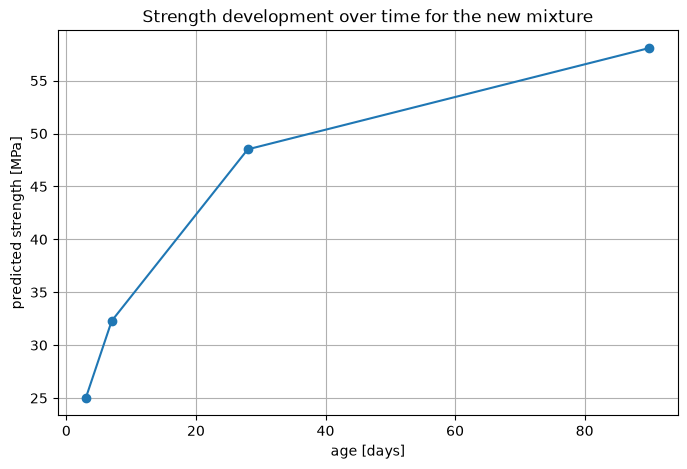

In [20]:
# describe a random new mixture
new_mix = pd.DataFrame([{
    "cement": 350, "slag": 100, "flyash": 0, "water": 175, "superplasticizer": 8,
    "coarseaggregate": 1000, "fineaggregate": 750, "age": 28,
}])[X.columns]

# predict with the random forest
prediction = forest.predict(new_mix)[0]
tree_preds = np.array([t.predict(new_mix.values)[0] for t in forest.estimators_])
print(f"Predicted compressive strength: {prediction:.1f} MPa")
print(f"Spread of the individual trees: {tree_preds.std():.1f} MPa (range {tree_preds.min():.1f}-{tree_preds.max():.1f} MPa)")

# plot how strenght develops over time
ages = [3, 7, 28, 90]
strengths = [forest.predict(new_mix.assign(age=age))[0] for age in ages]
for age, strength in zip(ages, strengths):
    print(f"  age {age:>2} days: {strength:.1f} MPa")

plt.figure(figsize=(8, 5))
plt.plot(ages, strengths, marker='o')
plt.xlabel("age [days]")
plt.ylabel("predicted strength [MPa]")
plt.title("Strength development over time for the new mixture")
plt.grid(True)
plt.show()

# $\mathrm{17.0\ Discussion\ and\ Summary}$



> **Task:** Discuss the results: Which model would you choose, and why? What are the limits of the models?

*Which model to choose?*
I would use the **random forest** as it has the best performance of all the models that we uses here. A downside is, that the random forest is hard to interpret. If interpretability really matters, a polynomial regression is also a good choice.

*Findings*
- Cement content, superplasticizer, age and water are the most important features. This matches concrete engineering: more cement --> stronger, more water --> weaker (Abrams' law), strength grows with age.
- The relationships are not linear (see scatter plots). Linear models therefore perform worst
- Reducing to 4 features costs up to about 0.1 R² for the linear and polynomial models and only a little for the decision tree. Only k-NN improved slightly.
